In [2]:
from pandas import read_csv,to_datetime
from matplotlib.pyplot import plot
from lab01utils import download_file_from_github

## Data source

The microplastic observations (`data/processed/obs_evangelou2026-revised.csv`) come from:

> Hough, I. (2026). *GEOS-Chem-IGE/hough2026_atmo-plast-emis_harmonize: v1.0.1* [Software]. Zenodo. https://doi.org/10.5281/zenodo.23046811

The file was downloaded from the matching GitHub commit
`a009a98f37adb85be02b9f3cf7c3de095ce3f444` using `download_microplastics_data.py`.

In [6]:
# Download the data file from GitHub
repository = "GEOS-Chem-IGE/hough2026_atmo-plast-emis_harmonize"
commit = "a0ba5c3a6a5e0271ef9860ea8a5f8b73fce0e44d"
filepath = "data/processed/obs_evangelou2026-revised.csv"

download_file_from_github(repository, commit, filepath)

In [7]:
# Read the data
data = read_csv("obs_evangelou2026-revised.csv")

In [8]:
data.head()

,author,year,doi,shape,measure,height,grid_lat,grid_lon,lat,lon,start_date,end_date,duration,number,number_units,n_obs,n_loc
0,Abbasi,2019,https://doi.org/10.1016/j.envpol.2018.10.039,fiber,concentration,NaN,28.0,52.5,27.310000,52.330000,2017-07-31,2017-08-28,8 days,1.155695,particle/m3,8,1
1,Abbasi,2023,https://doi.org/10.1016/j.jes.2022.02.044,fiber,concentration,NaN,32.0,47.5,31.417333,48.672000,2019-08-28,2019-12-23,25 days,0.006872,particle/m3,25,2
2,Akhbarizadeh,2021,https://doi.org/10.1016/j.envres.2020.110339,fiber,concentration,NaN,28.0,50.0,28.979600,50.834300,2017-01-04,2017-09-20,12 days,1.325833,particle/m3,12,1
3,Allen,2020,https://doi.org/10.1371/journal.pone.0232746,sphere,concentration,NaN,44.0,-2.5,44.216667,-1.283333,2018-10-05,2018-10-13,8 days,6.265435,particle/m3,8,1
4,Allen,2021,https://doi.org/10.1038/s41467-021-27454-7,fiber,concentration,NaN,42.0,0.0,42.936802,0.141170,2017-06-23,2017-10-23,97 days,0.070233,particle/m3,15,1


In [9]:
data.columns

Index(['author', 'year', 'doi', 'shape', 'measure', 'height', 'grid_lat',
       'grid_lon', 'lat', 'lon', 'start_date', 'end_date', 'duration',
       'number', 'number_units', 'n_obs', 'n_loc'],
      dtype='str')

In [10]:
conc = data[data["measure"] == "concentration"].copy()

In [11]:
conc["sample_year"] = to_datetime(conc["start_date"]).dt.year

In [12]:
conc_avg_all = conc.groupby("sample_year")["number"].mean()
print(conc_avg_all)

sample_year
2015      0.000758
2016      0.168552
2017      0.678910
2018    572.349397
2019     20.751784
2020      0.038536
2021      9.097975
2022    151.031098
2023      1.338079
Name: number, dtype: float64


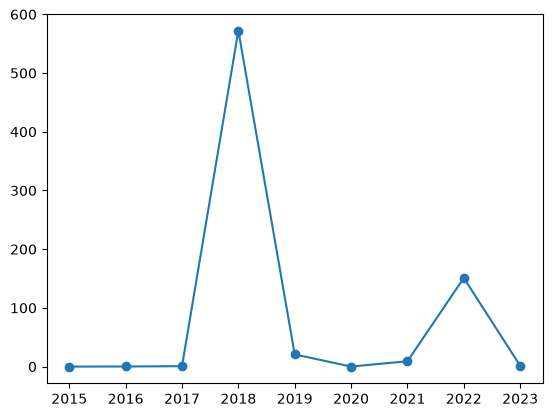

In [13]:
plot(conc_avg_all.index, conc_avg_all.values, marker="o", linestyle="-")

In [14]:
# Atmospheric deposition rates as a function of year
data["measure"].unique()

<StringArray>
['concentration', 'deposition']
Length: 2, dtype: str

In [15]:
dep = data[data["measure"] == "deposition"].copy()
dep["sample_year"] = to_datetime(dep["start_date"]).dt.year
dep_avg_all = dep.groupby("sample_year")["number"].mean()
print(dep_avg_all)

sample_year
2014     93.296703
2016     47.352060
2017     65.254024
2018    201.003319
2019    370.113426
2020     60.723212
2021    264.096033
2022    145.500000
2023     22.733333
Name: number, dtype: float64


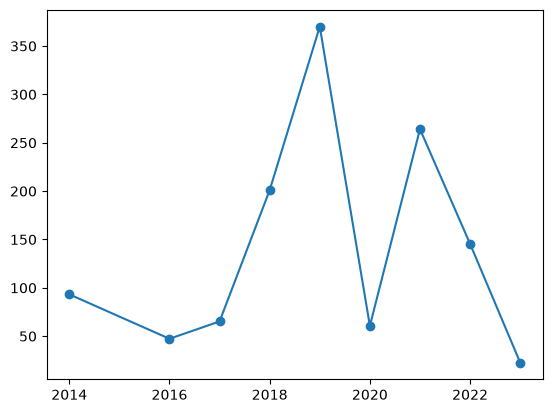

In [16]:
plot(dep_avg_all.index, dep_avg_all.values, marker="o", linestyle="-")

In [18]:
conc_avg = conc["number"].mean()
dep_avg = dep["number"].mean()
print(f"Average atmospheric microplastics composition = {conc_avg:.0f} particles/m3")
print(f"Average microplastics deposition rate = {dep_avg:.0f} particles/m2/d")

Average atmospheric microplastics composition = 45 particles/m3
Average microplastics deposition rate = 169 particles/m2/d
